In [2]:
import pandas as pd

In [5]:
import os

In [7]:
print("Current directory:")
print(os.getcwd())



Current directory:
C:\Users\Rahul\Desktop\customer-churn-prediction\notebooks


In [8]:
print("\nFiles and folders here:")
print(os.listdir())


Files and folders here:
['.ipynb_checkpoints', '01_data_analysis.py.ipynb']


In [9]:
import os

print(os.path.exists("data"))

False


In [10]:
import os

# Go to the main project folder
os.chdir("..")

print("Current directory:", os.getcwd())
print("Folders:", os.listdir())

Current directory: C:\Users\Rahul\Desktop\customer-churn-prediction
Folders: ['app.py', 'data', 'notebooks', 'requirements.txt']


In [11]:
import os

print(os.listdir("data"))

['Telco-Customer-Churn.csv']


In [12]:
import os

print(os.listdir("data"))

['Telco-Customer-Churn.csv']


In [13]:
import pandas as pd
import os

csv_files = [
    f for f in os.listdir("data")
    if f.lower().endswith(".csv")
]

print("CSV files:", csv_files)

CSV files: ['Telco-Customer-Churn.csv']


In [14]:
df = pd.read_csv(os.path.join("data", csv_files[0]))

print(df.head())
print("Dataset shape:", df.shape)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [16]:
df = pd.read_csv(
    "data/Telco-Customer-Churn.csv"
)

In [17]:
# 1. Dataset ki first 5 rows
display(df.head())

# 2. Total rows and columns
print("Dataset shape:", df.shape)

# 3. All column names
print("\nColumn names:")
print(df.columns.tolist())

# 4. Data types and non-null values
print("\nDataset information:")
df.info()

# 5. Missing values
print("\nMissing values:")
print(df.isnull().sum())

# 6. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [18]:
# Count customers who left and stayed
print(df["Churn"].value_counts())

# Percentage of each category
print("\nChurn percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


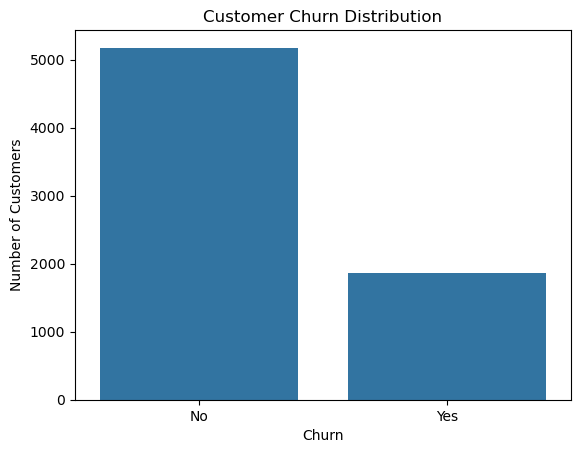

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [20]:

import pandas as pd

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Show rows with missing TotalCharges
display(df[df["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
])

Missing TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [21]:
# Fill zero charges only for customers with zero tenure
mask = df["TotalCharges"].isnull() & (df["tenure"] == 0)

df.loc[mask, "TotalCharges"] = 0

# Verify remaining missing values
print("Remaining missing values:")
print(df.isnull().sum())

# Confirm data type
print("\nTotalCharges data type:", df["TotalCharges"].dtype)

Remaining missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

TotalCharges data type: float64


In [22]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)

display(df.head())

Dataset shape: (7043, 21)

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
print(df.columns.tolist())
print(df[["customerID", "TotalCharges", "Churn"]].head(10))
print("\nMissing values:")
print(df.isnull().sum())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
   customerID  TotalCharges Churn
0  7590-VHVEG         29.85    No
1  5575-GNVDE       1889.50    No
2  3668-QPYBK        108.15   Yes
3  7795-CFOCW       1840.75    No
4  9237-HQITU        151.65   Yes
5  9305-CDSKC        820.50   Yes
6  1452-KIOVK       1949.40    No
7  6713-OKOMC        301.90    No
8  7892-POOKP       3046.05   Yes
9  6388-TABGU       3487.95    No

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0

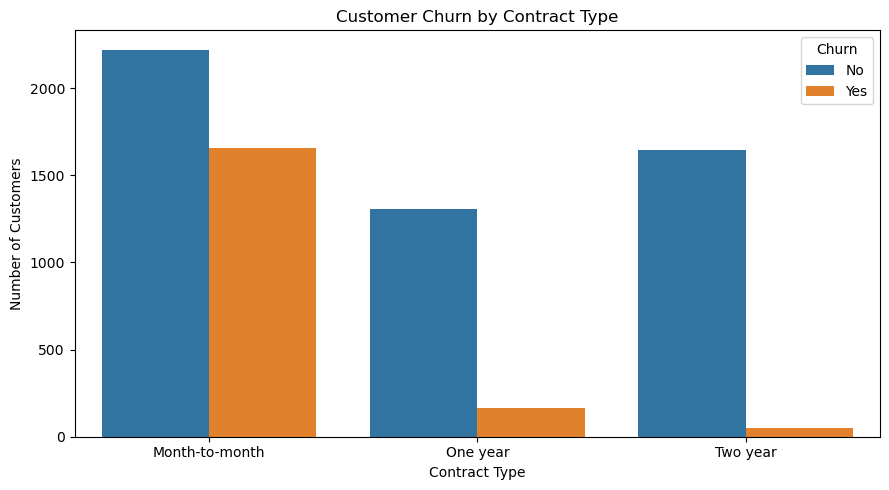

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [25]:
churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_contract.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


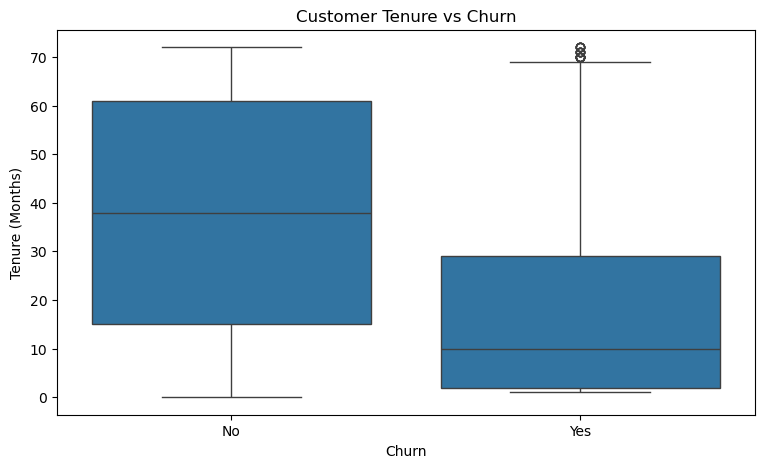

In [26]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

In [27]:
from sklearn.model_selection import train_test_split

# Remove customerID because it is only an identifier
X = df.drop(columns=["Churn", "customerID"])

# Target variable
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [28]:
X_train, X_test, y_train, y_test = train_test_ split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 5634
Testing records: 1409


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1-score: 0.604

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[926 109]
 [165 209]]


In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall:", round(recall_score(y_test, rf_pred), 4))
print("F1-score:", round(f1_score(y_test, rf_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

Random Forest Results
---------------------
Accuracy: 0.7828
Precision: 0.6189
Recall: 0.4733
F1-score: 0.5364
ROC-AUC: 0.8232


In [32]:
import pandas as pd

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, model.predict(X_test)),
        "Precision": precision_score(y_test, model.predict(X_test)),
        "Recall": recall_score(y_test, model.predict(X_test)),
        "F1-score": f1_score(y_test, model.predict(X_test))
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred),
        "Recall": recall_score(y_test, rf_pred),
        "F1-score": f1_score(y_test, rf_pred)
    }
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,Random Forest,0.7828,0.6189,0.4733,0.5364


In [33]:
import os
import joblib

# Create models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Save the trained Logistic Regression pipeline
joblib.dump(
    model,
    "../models/churn_pipeline.joblib"
)

print("Best model saved successfully!")

Best model saved successfully!


In [34]:
import pandas as pd

preprocessor_fitted = model.named_steps["preprocessing"]
classifier = model.named_steps["classifier"]

feature_names = preprocessor_fitted.get_feature_names_out()
coefficients = classifier.coef_[0]

importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

importance["Abs_Coefficient"] = importance["Coefficient"].abs()

importance = importance.sort_values(
    "Abs_Coefficient",
    ascending=False
)

display(importance.head(15))

,Feature,Coefficient,Abs_Coefficient
1,numeric__tenure,-1.257539,1.257539
38,categorical__Contract_Two year,-0.776594,0.776594
15,categorical__InternetService_DSL,-0.648646,0.648646
16,categorical__InternetService_Fiber optic,0.634195,0.634195
2,numeric__MonthlyCharges,-0.591863,0.591863
36,categorical__Contract_Month-to-month,0.582883,0.582883
3,numeric__TotalCharges,0.536253,0.536253
39,categorical__PaperlessBilling_No,-0.343227,0.343227
25,categorical__DeviceProtection_No internet service,-0.300104,0.300104
17,categorical__InternetService_No,-0.300104,0.300104


In [35]:
import os

os.makedirs("../models", exist_ok=True)

print("Models folder created!")

Models folder created!


In [36]:
import joblib
import os

model_path = "../models/churn_pipeline.joblib"

joblib.dump(model, model_path)

print("Model saved successfully!")
print("File exists:", os.path.exists(model_path))

FileNotFoundError: [Errno 2] No such file or directory: '../models/churn_pipeline.joblib'

In [37]:
import os

print("Current folder:", os.getcwd())
print("Model file exists:", os.path.exists(
    "../models/churn_pipeline.joblib"
))

Current folder: C:\Users\Rahul\Desktop\customer-churn-prediction
Model file exists: False


In [38]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("Project ke andar files/folders:")

for item in Path.cwd().iterdir():
    print(item.name)

Current folder: C:\Users\Rahul\Desktop\customer-churn-prediction
Project ke andar files/folders:
app.py
data
models
notebooks
requirements.txt


In [39]:
from pathlib import Path

models_dir = Path.cwd() / "models"

print("Models folder exists:", models_dir.exists())
print("Files inside models folder:")

for file in models_dir.iterdir():
    print(file.name)

Models folder exists: True
Files inside models folder:
churn_pipeline.joblib


In [40]:
import joblib
from pathlib import Path

model_path = Path.cwd() / "models" / "churn_pipeline.joblib"

saved_model = joblib.load(model_path)

print("Model loaded successfully!")
print("File exists:", model_path.exists())
print("Model steps:", saved_model.named_steps.keys())

Model loaded successfully!
File exists: True
Model steps: dict_keys(['preprocessing', 'classifier'])


In [41]:
sample = X_test.iloc[[0]]

prediction = saved_model.predict(sample)[0]
probability = saved_model.predict_proba(sample)[0][1]

print("Predicted Churn:", "Yes" if prediction == 1 else "No")
print("Churn Probability:", round(probability * 100, 2), "%")

Predicted Churn: No
Churn Probability: 4.59 %


In [43]:

from pathlib import Path

app_path = Path.cwd() / "app.py"

print(app_path.read_text(encoding="utf-8"))

In [44]:

from pathlib import Path

app_path = Path.cwd() / "app.py"

print("File exists:", app_path.exists())
print("File size:", app_path.stat().st_size, "bytes")
print("File content:")
print(repr(app_path.read_text(encoding="utf-8")))

File exists: True
File size: 0 bytes
File content:
''


In [45]:
from pathlib import Path

app_code = r'''
import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

st.title("Customer Churn Prediction")
st.write("Predict customer churn risk using machine learning.")

MODEL_PATH = Path(__file__).resolve().parent / "models" / "churn_pipeline.joblib"

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

model = load_model()

st.subheader("Enter Customer Details")

with st.form("customer_form"):
    col1, col2 = st.columns(2)

    with col1:
        gender = st.selectbox("Gender", ["Male", "Female"])
        senior_citizen = st.selectbox("Senior Citizen", [0, 1])
        partner = st.selectbox("Has Partner?", ["Yes", "No"])
        dependents = st.selectbox("Has Dependents?", ["Yes", "No"])
        tenure = st.slider("Tenure (months)", 0, 72, 12)
        phone_service = st.selectbox("Phone Service", ["Yes", "No"])
        multiple_lines = st.selectbox(
            "Multiple Lines", ["No", "Yes", "No phone service"]
        )
        internet_service = st.selectbox(
            "Internet Service", ["DSL", "Fiber optic", "No"]
        )
        online_security = st.selectbox(
            "Online Security", ["Yes", "No", "No internet service"]
        )
        online_backup = st.selectbox(
            "Online Backup", ["Yes", "No", "No internet service"]
        )

    with col2:
        device_protection = st.selectbox(
            "Device Protection", ["Yes", "No", "No internet service"]
        )
        tech_support = st.selectbox(
            "Tech Support", ["Yes", "No", "No internet service"]
        )
        streaming_tv = st.selectbox(
            "Streaming TV", ["Yes", "No", "No internet service"]
        )
        streaming_movies = st.selectbox(
            "Streaming Movies", ["Yes", "No", "No internet service"]
        )
        contract = st.selectbox(
            "Contract", ["Month-to-month", "One year", "Two year"]
        )
        paperless_billing = st.selectbox("Paperless Billing", ["Yes", "No"])
        payment_method = st.selectbox(
            "Payment Method",
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ]
        )
        monthly_charges = st.number_input(
            "Monthly Charges", min_value=0.0, max_value=2000.0, value=70.0
        )
        total_charges = st.number_input(
            "Total Charges", min_value=0.0, max_value=100000.0, value=840.0
        )

    submitted = st.form_submit_button("Predict Churn")

if submitted:
    customer = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": senior_citizen,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone_service,
        "MultipleLines": multiple_lines,
        "InternetService": internet_service,
        "OnlineSecurity": online_security,
        "OnlineBackup": online_backup,
        "DeviceProtection": device_protection,
        "TechSupport": tech_support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless_billing,
        "PaymentMethod": payment_method,
        "MonthlyCharges": monthly_charges,
        "TotalCharges": total_charges
    }])

    try:
        prediction = int(model.predict(customer)[0])
        probability = float(model.predict_proba(customer)[0][1])

        st.subheader("Prediction Result")
        st.metric("Churn Probability", f"{probability:.2%}")

        if prediction == 1:
            st.error("Prediction: Customer may churn.")
        else:
            st.success("Prediction: Customer is unlikely to churn.")

        st.caption(
            "This is a machine-learning estimate, not a guarantee "
            "of customer behavior."
        )
    except Exception as error:
        st.error(f"Prediction failed: {error}")
'''

app_path = Path.cwd() / "app.py"
app_path.write_text(app_code.strip() + "\n", encoding="utf-8")

print("Dashboard code saved!")
print("File size:", app_path.stat().st_size, "bytes")
print("Location:", app_path.resolve())

Dashboard code saved!
File size: 4186 bytes
Location: C:\Users\Rahul\Desktop\customer-churn-prediction\app.py


In [46]:
cd /d "C:\Users\Rahul\Desktop\customer-churn-prediction"

[WinError 123] The filename, directory name, or volume label syntax is incorrect: '/d C:\\Users\\Rahul\\Desktop\\customer-churn-prediction'
C:\Users\Rahul\Desktop\customer-churn-prediction\notebooks


In [47]:

import sklearn
import sys

print("Python path:", sys.executable)
print("Scikit-learn version:", sklearn.__version__)

Python path: C:\Users\Rahul\anaconda3\python.exe
Scikit-learn version: 1.6.1


In [48]:
import joblib
from pathlib import Path
import sklearn

model_path = Path.cwd() / "models" / "churn_pipeline.joblib"

print("Scikit-learn:", sklearn.__version__)
print("Model path:", model_path)
print("Model exists:", model_path.exists())

Scikit-learn: 1.6.1
Model path: C:\Users\Rahul\Desktop\customer-churn-prediction\models\churn_pipeline.joblib
Model exists: True


In [49]:
joblib.dump(model, model_path)
print("Model saved successfully!")

Model saved successfully!


In [50]:

import sys
print(sys.executable)

C:\Users\Rahul\anaconda3\python.exe


In [51]:
import sys

print("Python location is:")
print(sys.executable)

Python location is:
C:\Users\Rahul\anaconda3\python.exe


In [52]:

from pathlib import Path
import shutil

project_dir = Path.cwd()
app_path = project_dir / "app.py"
backup_path = project_dir / "app_backup.py"

shutil.copy2(app_path, backup_path)

print("Backup created:", backup_path.exists())
print("Backup location:", backup_path)

Backup created: True
Backup location: C:\Users\Rahul\Desktop\customer-churn-prediction\app_backup.py


In [53]:

from pathlib import Path

app_code = r'''
import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

st.set_page_config(
    page_title="ChurnSense | Customer Analytics",
    page_icon="📊",
    layout="wide"
)

st.markdown("""
<style>
.block-container {
    padding-top: 2rem;
    padding-bottom: 2rem;
}
[data-testid="stMetric"] {
    background: #18212f;
    padding: 18px;
    border-radius: 12px;
    border: 1px solid #334155;
}
.stButton > button {
    width: 100%;
    border-radius: 8px;
    font-weight: 600;
    min-height: 45px;
}
</style>
""", unsafe_allow_html=True)

MODEL_PATH = Path(__file__).resolve().parent / "models" / "churn_pipeline.joblib"

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

model = load_model()

st.title("📊 ChurnSense")
st.caption("Customer Churn Prediction & Retention Analytics")
st.divider()

st.subheader("Customer Information")
st.write("Enter customer details to estimate their churn risk.")

with st.form("customer_form"):
    col1, col2, col3 = st.columns(3)

    with col1:
        gender = st.selectbox("Gender", ["Male", "Female"])
        senior_citizen = st.selectbox("Senior Citizen", [0, 1])
        partner = st.selectbox("Partner", ["Yes", "No"])
        dependents = st.selectbox("Dependents", ["Yes", "No"])
        tenure = st.slider("Tenure (months)", 0, 72, 12)
        phone_service = st.selectbox("Phone Service", ["Yes", "No"])
        multiple_lines = st.selectbox(
            "Multiple Lines", ["No", "Yes", "No phone service"]
        )

    with col2:
        internet_service = st.selectbox(
            "Internet Service", ["DSL", "Fiber optic", "No"]
        )
        online_security = st.selectbox(
            "Online Security", ["Yes", "No", "No internet service"]
        )
        online_backup = st.selectbox(
            "Online Backup", ["Yes", "No", "No internet service"]
        )
        device_protection = st.selectbox(
            "Device Protection", ["Yes", "No", "No internet service"]
        )
        tech_support = st.selectbox(
            "Tech Support", ["Yes", "No", "No internet service"]
        )
        streaming_tv = st.selectbox(
            "Streaming TV", ["Yes", "No", "No internet service"]
        )
        streaming_movies = st.selectbox(
            "Streaming Movies", ["Yes", "No", "No internet service"]
        )

    with col3:
        contract = st.selectbox(
            "Contract", ["Month-to-month", "One year", "Two year"]
        )
        paperless_billing = st.selectbox(
            "Paperless Billing", ["Yes", "No"]
        )
        payment_method = st.selectbox(
            "Payment Method",
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ]
        )
        monthly_charges = st.number_input(
            "Monthly Charges ($)",
            min_value=0.0,
            max_value=2000.0,
            value=70.0,
            step=5.0
        )
        total_charges = st.number_input(
            "Total Charges ($)",
            min_value=0.0,
            max_value=100000.0,
            value=840.0,
            step=50.0
        )

    submitted = st.form_submit_button("🔍 Predict Customer Churn")

if submitted:
    customer = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": senior_citizen,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone_service,
        "MultipleLines": multiple_lines,
        "InternetService": internet_service,
        "OnlineSecurity": online_security,
        "OnlineBackup": online_backup,
        "DeviceProtection": device_protection,
        "TechSupport": tech_support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless_billing,
        "PaymentMethod": payment_method,
        "MonthlyCharges": monthly_charges,
        "TotalCharges": total_charges
    }])

    try:
        prediction = int(model.predict(customer)[0])
        probability = float(model.predict_proba(customer)[0][1])
        risk = "High" if probability >= 0.60 else (
            "Medium" if probability >= 0.30 else "Low"
        )

        st.divider()
        st.subheader("Prediction Results")

        metric1, metric2, metric3 = st.columns(3)
        metric1.metric("Churn Probability", f"{probability:.1%}")
        metric2.metric("Predicted Outcome", "Churn" if prediction == 1 else "No Churn")
        metric3.metric("Risk Indicator", risk)

        st.progress(probability, text=f"Estimated churn probability: {probability:.1%}")

        if prediction == 1:
            st.error("This customer is predicted to churn. Consider reviewing retention options.")
        else:
            st.success("This customer is predicted not to churn.")

        st.caption(
            "Risk bands are illustrative thresholds. Predictions are estimates, "
            "not guarantees of future customer behavior."
        )

    except Exception as error:
        st.error(f"Prediction failed: {error}")

st.divider()
st.caption("ChurnSense | Machine Learning Demo | Built with Python and Streamlit")
'''

project_dir = Path.cwd()
app_path = project_dir / "app.py"
app_path.write_text(app_code.strip() + "\n", encoding="utf-8")

print("Professional dashboard code saved!")
print("File size:", app_path.stat().st_size, "bytes")
print("Backup remains:", (project_dir / "app_backup.py").exists())

Professional dashboard code saved!
File size: 5443 bytes
Backup remains: True


In [54]:
from pathlib import Path

requirements = """streamlit
pandas
numpy
joblib
scikit-learn==1.6.1
"""

requirements_path = Path.cwd() / "requirements.txt"
requirements_path.write_text(requirements, encoding="utf-8")

print("Requirements file updated!")
print(requirements_path.read_text(encoding="utf-8"))

Requirements file updated!
streamlit
pandas
numpy
joblib
scikit-learn==1.6.1

